# 05 · Final Results and Project Demonstration

## Propagation-Based Fake News Detection Using Graph Neural Networks

This notebook consolidates the experimental results obtained from the previous four notebooks.

The project investigates how textual information and propagation structure can be used for fake news detection. We evaluate two conventional machine learning baselines, compare three graph neural network architectures, and investigate whether explicitly calculated propagation statistics improve GNN performance.

The experiments use the PolitiFact and GossipCop datasets from the UPFD framework.

### Experimental workflow

1. Dataset exploration and computational analysis
2. Text-only MLP and propagation-only Random Forest baselines
3. GCN, GAT and GraphSAGE comparison
4. Propagation-statistics extension
5. Consolidated results, visualizations and conclusions

This notebook uses previously saved experimental results. No model training is performed here.

## 1. Environment and Result Loading

We begin by importing the libraries required for loading, analysing and visualizing the saved experimental results.

All result files are loaded from the project's existing `results` directory. The original datasets and model checkpoints are not required for this notebook.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

DATASETS = ["politifact", "gossipcop"]

DATASET_TITLES = {
    "politifact": "PolitiFact",
    "gossipcop": "GossipCop"
}

# Locate project root
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()

    for candidate in [start, *start.parents]:
        if (candidate / "data" / "upfd").is_dir():
            return candidate

    for candidate in [start, *start.parents]:
        if (candidate / "results" / "metrics").is_dir():
            return candidate

    raise FileNotFoundError(
        "Project root not found. Run this notebook from inside "
        "the FakeNews-detection-GNN project."
    )

PROJECT_ROOT = find_project_root()

RESULTS_DIR = PROJECT_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"

BASELINE_DIR = METRICS_DIR / "baselines"
GNN_DIR = METRICS_DIR / "gnn"
EXTENSION_DIR = METRICS_DIR / "extension"

FINAL_FIG_DIR = FIGURES_DIR / "final_results"
FINAL_FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("Results dir  :", RESULTS_DIR)
print("Baseline dir :", BASELINE_DIR)
print("GNN dir      :", GNN_DIR)
print("Extension dir:", EXTENSION_DIR)

Project root : C:\Users\shara\FakeNews-detection-GNN
Results dir  : C:\Users\shara\FakeNews-detection-GNN\results
Baseline dir : C:\Users\shara\FakeNews-detection-GNN\results\metrics\baselines
GNN dir      : C:\Users\shara\FakeNews-detection-GNN\results\metrics\gnn
Extension dir: C:\Users\shara\FakeNews-detection-GNN\results\metrics\extension


In [2]:
required_files = [
    METRICS_DIR / "dataset_summary.csv",
    METRICS_DIR / "computational_summary.csv",
    BASELINE_DIR / "baseline_comparison.csv",
    GNN_DIR / "gnn_metrics.csv",
    GNN_DIR / "gnn_config.json",
    GNN_DIR / "best_gnn_by_validation.json",
    EXTENSION_DIR / "extension_metrics.csv",
    EXTENSION_DIR / "extension_summary.csv",
    EXTENSION_DIR / "extension_difference.csv"
]

file_status = pd.DataFrame([
    {
        "File": str(p.relative_to(PROJECT_ROOT)),
        "Available": p.is_file()
    }
    for p in required_files
])

display(file_status)

missing = file_status.loc[~file_status["Available"], "File"].tolist()

if missing:
    raise FileNotFoundError(
        "Some required result files are missing:\n" + "\n".join(missing)
        + "\nRun the corresponding previous notebook first."
    )

print("All required result files are available.")

,File,Available
0,results\metrics\dataset_summary.csv,True
1,results\metrics\computational_summary.csv,True
2,results\metrics\baselines\baseline_comparison.csv,True
3,results\metrics\gnn\gnn_metrics.csv,True
4,results\metrics\gnn\gnn_config.json,True
5,results\metrics\gnn\best_gnn_by_validation.json,True
6,results\metrics\extension\extension_metrics.csv,True
7,results\metrics\extension\extension_summary.csv,True
8,results\metrics\extension\extension_difference...,True


All required result files are available.


In [3]:
DATASET_SUMMARY = pd.read_csv(METRICS_DIR / "dataset_summary.csv")
COMPUTE_SUMMARY = pd.read_csv(METRICS_DIR / "computational_summary.csv")

BASELINE_RESULTS = pd.read_csv(
    BASELINE_DIR / "baseline_comparison.csv"
)

GNN_METRICS = pd.read_csv(
    GNN_DIR / "gnn_metrics.csv"
)

GNN_CONFIG = json.loads(
    (GNN_DIR / "gnn_config.json").read_text(encoding="utf-8")
)

BEST_GNN_FILE = json.loads(
    (GNN_DIR / "best_gnn_by_validation.json").read_text(encoding="utf-8")
)

# The selection file stores dataset-wise models inside this key.
BEST_GNN = BEST_GNN_FILE["best_gnn_by_dataset"]

EXTENSION_METRICS = pd.read_csv(
    EXTENSION_DIR / "extension_metrics.csv"
)

EXTENSION_SUMMARY = pd.read_csv(
    EXTENSION_DIR / "extension_summary.csv"
)

EXTENSION_DIFFERENCE = pd.read_csv(
    EXTENSION_DIR / "extension_difference.csv"
)

print("Dataset summary:", DATASET_SUMMARY.shape)
print("Computational summary:", COMPUTE_SUMMARY.shape)
print("Baseline results:", BASELINE_RESULTS.shape)
print("GNN metrics:", GNN_METRICS.shape)
print("Extension metrics:", EXTENSION_METRICS.shape)

print("\nGNN configuration:")
display(pd.DataFrame([
    {"Parameter": k, "Value": str(v)}
    for k, v in GNN_CONFIG.items()
    if k != "cfg"
]))

print("\nValidation-selected GNN:")
display(pd.DataFrame([
    {"Dataset": DATASET_TITLES[k], "Selected GNN": v}
    for k, v in BEST_GNN.items()
]))


Dataset summary: (2, 19)
Computational summary: (2, 9)
Baseline results: (4, 11)
GNN metrics: (72, 24)
Extension metrics: (40, 16)

GNN configuration:


,Parameter,Value
0,setting,L1_max_root_as_stored
1,edge_mode,as_stored
2,readout,max
3,num_layers,1
4,root_fusion,True
5,batch_size,"{'politifact': 32, 'gossipcop': 64}"
6,eval_batch_size,"{'politifact': 64, 'gossipcop': 128}"
7,seeds,"[42, 43, 44, 45, 46]"



Validation-selected GNN:


,Dataset,Selected GNN
0,PolitiFact,GraphSAGE
1,GossipCop,GraphSAGE


## 2. Dataset Summary

The experiments use two datasets from the UPFD framework: PolitiFact and GossipCop.

These datasets differ considerably in their number of propagation graphs, nodes and edges. Understanding these differences is important when interpreting model performance and computational requirements.

We summarize the dataset sizes, graph characteristics and computational costs using the outputs saved by the dataset exploration notebook.

In [4]:
print("Dataset summary")
display(DATASET_SUMMARY)

print("Computational summary")
display(COMPUTE_SUMMARY)

Dataset summary


,dataset,total_graphs,train_graphs,val_graphs,test_graphs,class0_raw_label,class0_graphs,class1_raw_label,class1_graphs,fake_graphs,real_graphs,total_nodes,edges_in_A_txt,total_edges_coalesced,avg_nodes_per_graph,median_nodes_per_graph,avg_edges_per_graph,max_graph_size_nodes,bert_feature_dim
0,politifact,314,62,31,221,0.0000,157,1.0000,157,NaN,NaN,41054,40740,40740,130.7500,78.5000,129.7500,497,768
1,gossipcop,5464,1092,546,3826,0.0000,2732,1.0000,2732,NaN,NaN,314262,308798,308798,57.5200,49.0000,56.5200,199,768


Computational summary


,dataset,graphs,nodes,edges,feature_dim,features_dense_GiB,features_in_memory_MiB,load_time_s,graph_build_time_s
0,PolitiFact,314,41054,40740,768,0.1170,240.7000,4.1200,0.6100
1,GossipCop,5464,314262,308798,768,0.8990,1842.6000,32.0400,3.5800


Numeric dataset measurements: ['total_graphs', 'train_graphs', 'val_graphs', 'test_graphs', 'class0_raw_label', 'class0_graphs', 'class1_raw_label', 'class1_graphs', 'fake_graphs', 'real_graphs', 'total_nodes', 'edges_in_A_txt', 'total_edges_coalesced', 'avg_nodes_per_graph', 'median_nodes_per_graph', 'avg_edges_per_graph', 'max_graph_size_nodes', 'bert_feature_dim']


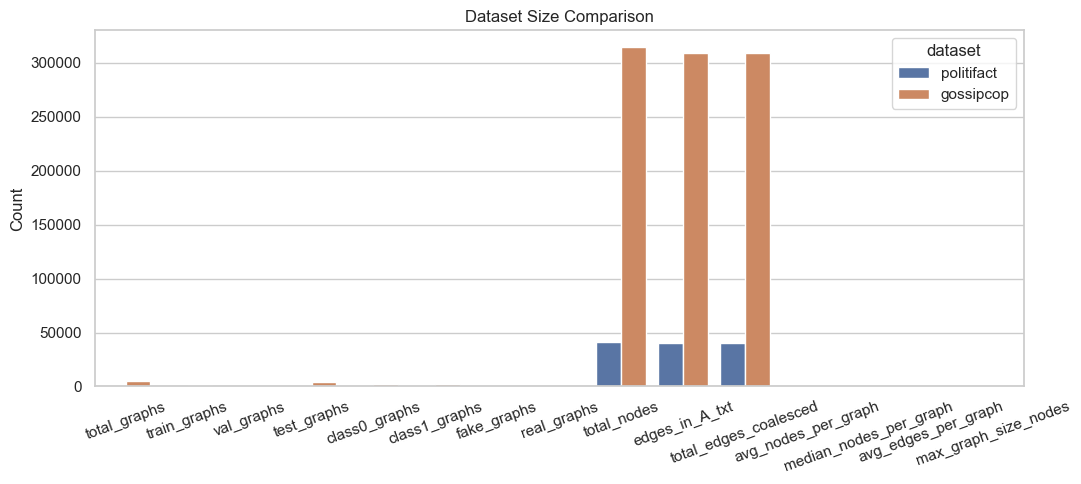

In [5]:
# Identify the dataset-name column
dataset_col = next(
    (c for c in DATASET_SUMMARY.columns
     if c.lower() in ["dataset", "dataset_name", "name"]),
    None
)

if dataset_col is None:
    raise ValueError(
        f"Cannot identify dataset column. Available columns: "
        f"{DATASET_SUMMARY.columns.tolist()}"
    )

numeric_cols = DATASET_SUMMARY.select_dtypes(include=np.number).columns.tolist()

print("Numeric dataset measurements:", numeric_cols)

plot_cols = [
    c for c in numeric_cols
    if any(term in c.lower() for term in ["graph", "node", "edge"])
]

if plot_cols:
    plot_data = DATASET_SUMMARY.melt(
        id_vars=dataset_col,
        value_vars=plot_cols,
        var_name="Measurement",
        value_name="Count"
    )

    fig, ax = plt.subplots(figsize=(11, 5))

    sns.barplot(
        data=plot_data,
        x="Measurement",
        y="Count",
        hue=dataset_col,
        ax=ax
    )

    ax.set_title("Dataset Size Comparison")
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=20)

    plt.tight_layout()
    plt.savefig(
        FINAL_FIG_DIR / "dataset_size_comparison.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
else:
    print("No graph/node/edge columns identified for plotting.")

### 2.1 Dataset observations

PolitiFact contains substantially fewer propagation graphs than GossipCop. Consequently, the two datasets represent different computational scales.

GossipCop requires more resources because it contains a much larger collection of propagation graphs and nodes.

The difference in dataset size also affects the reliability of evaluation metrics. In particular, a single misclassified graph has a much larger effect on accuracy for the smaller PolitiFact test set.

## 3. Baseline Model Results

We evaluate two baselines:

1. **Text-only MLP:** Uses the BERT representation of the root news node.
2. **Propagation-only Random Forest:** Uses structural statistics extracted from the propagation graph.

These baselines help distinguish the predictive contribution of textual information from that of propagation structure.

The reported values are mean test-set metrics across five random seeds.

In [6]:
baseline_display = BASELINE_RESULTS.copy()

baseline_columns = [
    "Dataset",
    "Model",
    "Accuracy",
    "Precision (macro)",
    "Recall (macro)",
    "Macro F1",
    "ROC-AUC",
    "seeds",
    "test graphs"
]

available = [
    c for c in baseline_columns
    if c in baseline_display.columns
]

display(
    baseline_display[available].round(4)
)

,Dataset,Model,Accuracy,Precision (macro),Recall (macro),Macro F1,ROC-AUC,seeds,test graphs
0,PolitiFact,Text-only MLP,0.8127,0.8220,0.8146,0.8118,0.8628,5,221
1,PolitiFact,Propagation-only RF,0.5195,0.5369,0.5255,0.4856,0.5590,5,221
2,GossipCop,Text-only MLP,0.7404,0.7454,0.7405,0.7391,0.8106,5,3826
3,GossipCop,Propagation-only RF,0.8152,0.8160,0.8152,0.8151,0.8881,5,3826


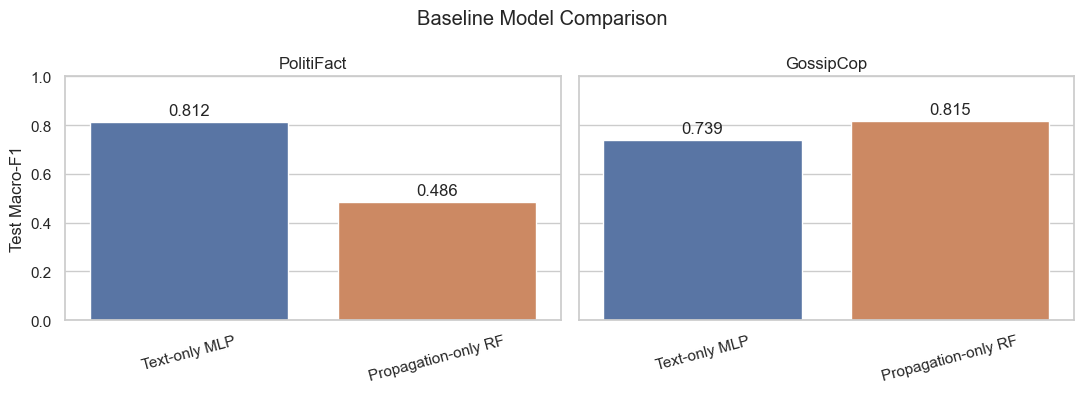

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, dataset in zip(axes, ["PolitiFact", "GossipCop"]):
    subset = BASELINE_RESULTS[
        BASELINE_RESULTS["Dataset"] == dataset
    ]

    sns.barplot(
        data=subset,
        x="Model",
        y="Macro F1",
        hue="Model",
        legend=False,
        ax=ax
    )

    ax.set_title(dataset)
    ax.set_xlabel("")
    ax.set_ylabel("Test Macro-F1")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=15)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3)

plt.suptitle("Baseline Model Comparison")
plt.tight_layout()

plt.savefig(
    FINAL_FIG_DIR / "baseline_macro_f1.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### 3.1 Baseline observations

The baseline results provide two different perspectives on fake news detection.

The text-only MLP evaluates whether the original news representation contains useful information for classification.

The propagation-only Random Forest investigates whether structural properties of the propagation graph can distinguish the two classes without using BERT node embeddings.

Differences between PolitiFact and GossipCop suggest that the usefulness of textual and propagation information may depend on the dataset.

## 4. Graph Neural Network Comparison

Three GNN architectures are evaluated:

- Graph Convolutional Network (GCN)
- Graph Attention Network (GAT)
- GraphSAGE

All three models use BERT node features and propagation graph edges.

The main comparison uses a shared experimental configuration, including the same number of layers, pooling method, root-feature fusion strategy and training protocol.

Model selection is based on mean validation macro-F1. Test-set performance is reported only after selection and is not used to choose the architecture.

In [8]:
gnn_test = GNN_METRICS[
    (GNN_METRICS["split"] == "test") &
    (GNN_METRICS["setting"] == GNN_CONFIG["setting"])
].copy()

gnn_val = GNN_METRICS[
    (GNN_METRICS["split"] == "val") &
    (GNN_METRICS["setting"] == GNN_CONFIG["setting"])
].copy()

metric_columns = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "roc_auc"
]

gnn_rows = []

for (dataset_key, model), group in gnn_test.groupby(
    ["dataset_key", "model"]
):
    val_group = gnn_val[
        (gnn_val["dataset_key"] == dataset_key) &
        (gnn_val["model"] == model)
    ]

    row = {
        "Dataset": DATASET_TITLES[dataset_key],
        "Model": model,
        "Seeds": group["seed"].nunique(),
        "Test graphs": int(group["n"].iloc[0])
    }

    for metric in metric_columns:
        row[f"{metric}_mean"] = group[metric].mean()
        row[f"{metric}_std"] = group[metric].std()

    row["Validation Macro-F1"] = val_group["f1_macro"].mean()

    gnn_rows.append(row)

GNN_SUMMARY = pd.DataFrame(gnn_rows)

display(GNN_SUMMARY.round(4))

,Dataset,Model,Seeds,Test graphs,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std,roc_auc_mean,roc_auc_std,Validation Macro-F1
0,GossipCop,GAT,5,3826,0.9629,0.0054,0.9630,0.0054,0.9629,0.0054,0.9629,0.0054,0.9914,0.0010,0.9600
1,GossipCop,GCN,5,3826,0.9491,0.0063,0.9491,0.0063,0.9491,0.0063,0.9491,0.0063,0.9854,0.0038,0.9531
2,GossipCop,GraphSAGE,5,3826,0.9664,0.0022,0.9665,0.0022,0.9664,0.0022,0.9664,0.0022,0.9935,0.0004,0.9703
3,PolitiFact,GAT,5,221,0.8226,0.0081,0.8267,0.0099,0.8238,0.0084,0.8224,0.0080,0.8811,0.0031,0.8697
4,PolitiFact,GCN,5,221,0.8244,0.0067,0.8283,0.0075,0.8256,0.0068,0.8242,0.0067,0.8882,0.0048,0.8697
5,PolitiFact,GraphSAGE,5,221,0.8226,0.0081,0.8292,0.0065,0.8242,0.0079,0.8221,0.0084,0.8853,0.0043,0.8764


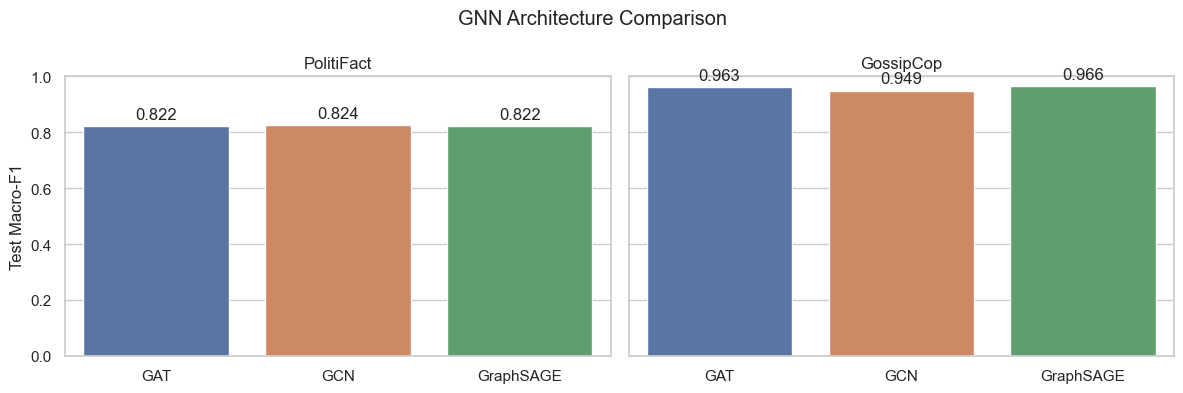

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, dataset in zip(axes, ["PolitiFact", "GossipCop"]):
    subset = GNN_SUMMARY[
        GNN_SUMMARY["Dataset"] == dataset
    ]

    sns.barplot(
        data=subset,
        x="Model",
        y="f1_macro_mean",
        hue="Model",
        legend=False,
        ax=ax
    )

    ax.set_title(dataset)
    ax.set_xlabel("")
    ax.set_ylabel("Test Macro-F1")
    ax.set_ylim(0, 1)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3)

plt.suptitle("GNN Architecture Comparison")
plt.tight_layout()

plt.savefig(
    FINAL_FIG_DIR / "gnn_macro_f1_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [10]:
selected_models = []

for dataset_key, model in BEST_GNN.items():
    selected_models.append({
        "Dataset": DATASET_TITLES[dataset_key],
        "Selected Model": model,
        "Selection Criterion": "Highest mean validation macro-F1"
    })

SELECTION_TABLE = pd.DataFrame(selected_models)

display(SELECTION_TABLE)

print("Test-set metrics are not used for architecture selection.")

,Dataset,Selected Model,Selection Criterion
0,PolitiFact,GraphSAGE,Highest mean validation macro-F1
1,GossipCop,GraphSAGE,Highest mean validation macro-F1


Test-set metrics are not used for architecture selection.


### 4.1 GNN comparison observations

The three GNN architectures use the same experimental configuration, allowing their performance to be compared under a controlled setting.

The validation-selected architecture is identified separately for each dataset.

Small differences between model scores should be interpreted carefully, particularly on PolitiFact, where the test set contains relatively few graphs.

A higher test score alone does not establish that an architecture is generally superior.

## 5. Overall Model Comparison

This section combines the two conventional baselines and the three GNN architectures.

The comparison helps us understand whether learning from propagation graphs provides an advantage over using only textual information or manually extracted graph statistics.

All reported values are test-set results averaged across the available random seeds.

The number of test graphs is also shown because evaluation on datasets with different test-set sizes should be interpreted carefully.

In [11]:
baseline_for_combined = BASELINE_RESULTS.copy()

baseline_for_combined = baseline_for_combined.rename(
    columns={
        "seeds": "Seeds",
        "test graphs": "Test graphs"
    }
)

baseline_for_combined["Family"] = "Baseline"

gnn_for_combined = GNN_SUMMARY.copy()

gnn_for_combined = gnn_for_combined.rename(
    columns={
        "accuracy_mean": "Accuracy",
        "precision_macro_mean": "Precision (macro)",
        "recall_macro_mean": "Recall (macro)",
        "f1_macro_mean": "Macro F1",
        "roc_auc_mean": "ROC-AUC"
    }
)

gnn_for_combined["Family"] = "GNN"

combined_columns = [
    "Dataset",
    "Model",
    "Family",
    "Accuracy",
    "Precision (macro)",
    "Recall (macro)",
    "Macro F1",
    "ROC-AUC",
    "Seeds",
    "Test graphs"
]

BASELINE_PART = baseline_for_combined[
    [c for c in combined_columns if c in baseline_for_combined.columns]
]

GNN_PART = gnn_for_combined[
    [c for c in combined_columns if c in gnn_for_combined.columns]
]

OVERALL_RESULTS = pd.concat(
    [BASELINE_PART, GNN_PART],
    ignore_index=True
)

model_order = [
    "Text-only MLP",
    "Propagation-only RF",
    "GCN",
    "GAT",
    "GraphSAGE"
]

OVERALL_RESULTS["Model"] = pd.Categorical(
    OVERALL_RESULTS["Model"],
    categories=model_order,
    ordered=True
)

OVERALL_RESULTS = OVERALL_RESULTS.sort_values(
    ["Dataset", "Model"]
).reset_index(drop=True)

display(OVERALL_RESULTS.round(4))

OVERALL_RESULTS.to_csv(
    METRICS_DIR / "final_overall_model_comparison.csv",
    index=False
)

,Dataset,Model,Family,Accuracy,Precision (macro),Recall (macro),Macro F1,ROC-AUC,Seeds,Test graphs
0,GossipCop,Text-only MLP,Baseline,0.7404,0.7454,0.7405,0.7391,0.8106,5,3826
1,GossipCop,Propagation-only RF,Baseline,0.8152,0.8160,0.8152,0.8151,0.8881,5,3826
2,GossipCop,GCN,GNN,0.9491,0.9491,0.9491,0.9491,0.9854,5,3826
3,GossipCop,GAT,GNN,0.9629,0.9630,0.9629,0.9629,0.9914,5,3826
4,GossipCop,GraphSAGE,GNN,0.9664,0.9665,0.9664,0.9664,0.9935,5,3826
5,PolitiFact,Text-only MLP,Baseline,0.8127,0.8220,0.8146,0.8118,0.8628,5,221
6,PolitiFact,Propagation-only RF,Baseline,0.5195,0.5369,0.5255,0.4856,0.5590,5,221
7,PolitiFact,GCN,GNN,0.8244,0.8283,0.8256,0.8242,0.8882,5,221
8,PolitiFact,GAT,GNN,0.8226,0.8267,0.8238,0.8224,0.8811,5,221
9,PolitiFact,GraphSAGE,GNN,0.8226,0.8292,0.8242,0.8221,0.8853,5,221


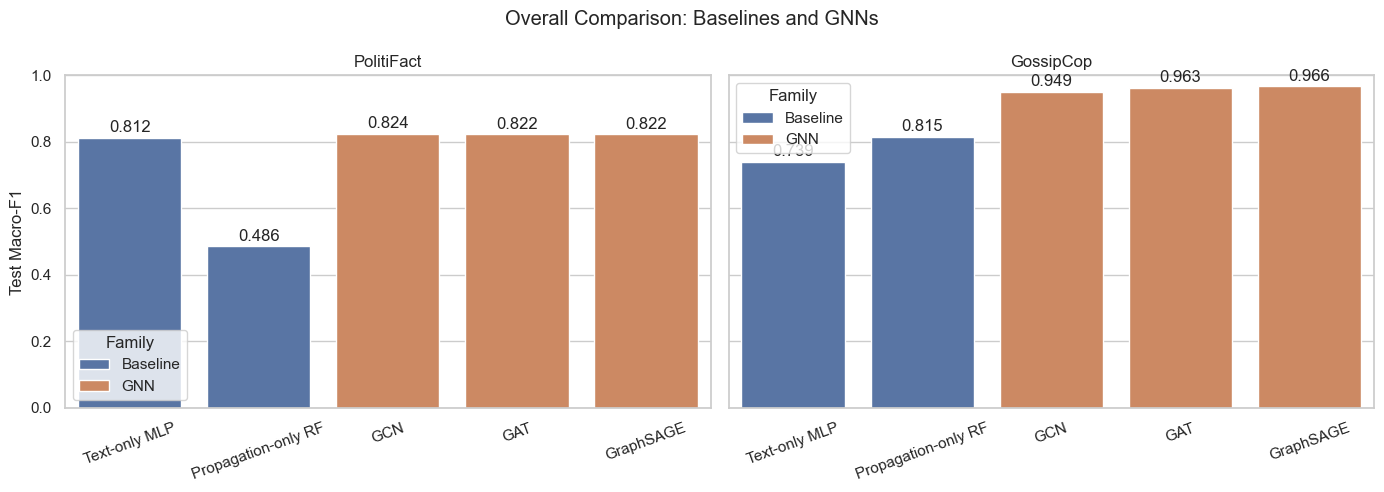

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, dataset in zip(axes, ["PolitiFact", "GossipCop"]):
    subset = OVERALL_RESULTS[
        OVERALL_RESULTS["Dataset"] == dataset
    ].copy()

    sns.barplot(
        data=subset,
        x="Model",
        y="Macro F1",
        hue="Family",
        ax=ax
    )

    ax.set_title(dataset)
    ax.set_xlabel("")
    ax.set_ylabel("Test Macro-F1")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=20)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=2)

plt.suptitle("Overall Comparison: Baselines and GNNs")
plt.tight_layout()

plt.savefig(
    FINAL_FIG_DIR / "overall_macro_f1_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

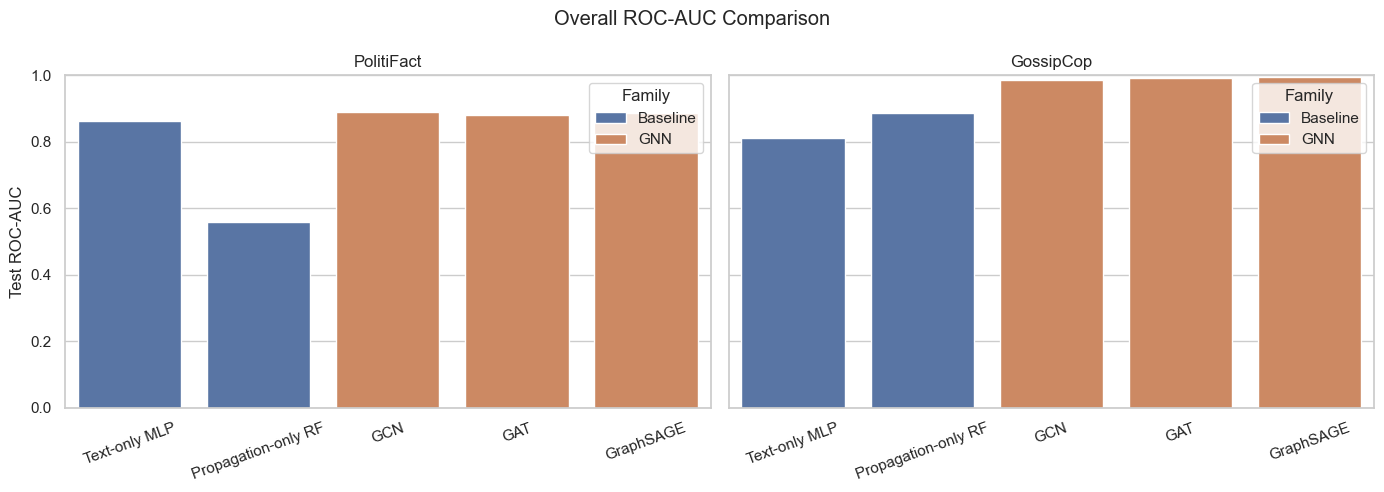

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, dataset in zip(axes, ["PolitiFact", "GossipCop"]):
    subset = OVERALL_RESULTS[
        OVERALL_RESULTS["Dataset"] == dataset
    ].copy()

    sns.barplot(
        data=subset,
        x="Model",
        y="ROC-AUC",
        hue="Family",
        ax=ax
    )

    ax.set_title(dataset)
    ax.set_xlabel("")
    ax.set_ylabel("Test ROC-AUC")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=20)

plt.suptitle("Overall ROC-AUC Comparison")
plt.tight_layout()

plt.savefig(
    FINAL_FIG_DIR / "overall_roc_auc_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### 5.1 Overall comparison observations

The combined results allow us to compare three types of information:

- Textual information from the root news representation.
- Explicit structural information from propagation statistics.
- Learned representations from the propagation graph using GNNs.

The results should be interpreted separately for PolitiFact and GossipCop because their dataset sizes and characteristics differ.

The comparison is descriptive. The reported test scores are not used to retune or select models.

## 6. Propagation Statistics Extension

The research extension investigates whether explicitly calculated propagation statistics improve the performance of the validation-selected GNN.

Two variants are compared:

1. **Best GNN:** BERT node features and propagation graph.
2. **Best GNN + statistics:** The same GNN representation combined with explicit propagation statistics.

The comparison uses the same five random seeds for both variants. The paired differences are calculated seed by seed.

This experiment tests whether manually calculated graph-level statistics provide useful additional information beyond the representation learned by the GNN.

In [14]:
print("Extension results")
display(EXTENSION_SUMMARY)

print("Paired differences")
display(EXTENSION_DIFFERENCE.round(4))

Extension results


,Dataset,GNN,Variant,Accuracy,Macro F1,ROC-AUC,seeds
0,PolitiFact,GraphSAGE,Best GNN,0.828 ± 0.009,0.828 ± 0.009,0.885 ± 0.006,5
1,PolitiFact,GraphSAGE,Best GNN + statistics,0.813 ± 0.053,0.811 ± 0.057,0.884 ± 0.014,5
2,GossipCop,GraphSAGE,Best GNN,0.966 ± 0.002,0.966 ± 0.002,0.994 ± 0.001,5
3,GossipCop,GraphSAGE,Best GNN + statistics,0.965 ± 0.005,0.965 ± 0.005,0.994 ± 0.000,5


Paired differences


,Dataset,GNN,Macro F1 without,Macro F1 with,Difference (mean),Difference (std),Seeds improved,Paired t-test p
0,PolitiFact,GraphSAGE,0.8278,0.8106,-0.0172,0.0603,2/5,0.5586
1,GossipCop,GraphSAGE,0.9659,0.9654,-0.0005,0.0045,3/5,0.8267


In [15]:
extension_test = EXTENSION_METRICS[
    (EXTENSION_METRICS["split"] == "test") &
    (EXTENSION_METRICS["setting"] == GNN_CONFIG["setting"])
].copy()

extension_rows = []

for dataset_key in DATASETS:
    subset = extension_test[
        extension_test["dataset_key"] == dataset_key
    ]

    without_stats = subset[
        subset["variant"] == "Best GNN"
    ][["seed", "f1_macro"]].rename(
        columns={"f1_macro": "without_stats"}
    )

    with_stats = subset[
        subset["variant"] == "Best GNN + statistics"
    ][["seed", "f1_macro"]].rename(
        columns={"f1_macro": "with_stats"}
    )

    paired = without_stats.merge(
        with_stats,
        on="seed",
        how="inner",
        validate="one_to_one"
    )

    paired["difference"] = (
        paired["with_stats"] - paired["without_stats"]
    )

    extension_rows.append({
        "Dataset": DATASET_TITLES[dataset_key],
        "Seeds compared": len(paired),
        "Macro-F1 without statistics": paired["without_stats"].mean(),
        "Macro-F1 with statistics": paired["with_stats"].mean(),
        "Mean paired difference": paired["difference"].mean(),
        "Std of paired difference": paired["difference"].std(),
        "Seeds improved": int((paired["difference"] > 0).sum()),
        "Seeds unchanged": int((paired["difference"] == 0).sum()),
        "Seeds decreased": int((paired["difference"] < 0).sum())
    })

PAIRED_EXTENSION = pd.DataFrame(extension_rows)

display(PAIRED_EXTENSION.round(4))

PAIRED_EXTENSION.to_csv(
    METRICS_DIR / "final_extension_paired_comparison.csv",
    index=False
)

,Dataset,Seeds compared,Macro-F1 without statistics,Macro-F1 with statistics,Mean paired difference,Std of paired difference,Seeds improved,Seeds unchanged,Seeds decreased
0,PolitiFact,5,0.8278,0.8106,-0.0172,0.0603,2,1,2
1,GossipCop,5,0.9659,0.9654,-0.0005,0.0045,3,0,2


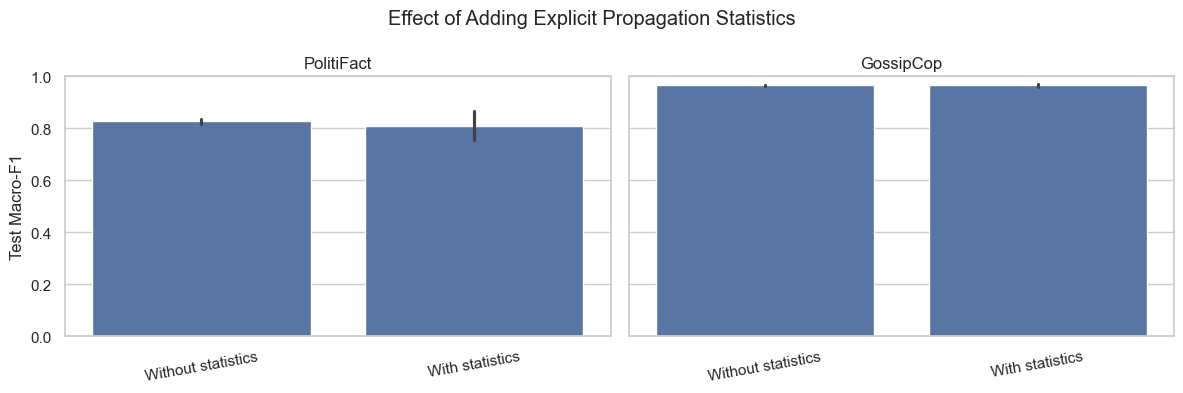

In [16]:
plot_data = extension_test.copy()

plot_data["Variant"] = plot_data["variant"].replace({
    "Best GNN": "Without statistics",
    "Best GNN + statistics": "With statistics"
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, dataset_key in zip(axes, DATASETS):
    subset = plot_data[
        plot_data["dataset_key"] == dataset_key
    ]

    sns.barplot(
        data=subset,
        x="Variant",
        y="f1_macro",
        errorbar="sd",
        ax=ax
    )

    ax.set_title(DATASET_TITLES[dataset_key])
    ax.set_xlabel("")
    ax.set_ylabel("Test Macro-F1")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=10)

plt.suptitle("Effect of Adding Explicit Propagation Statistics")
plt.tight_layout()

plt.savefig(
    FINAL_FIG_DIR / "propagation_statistics_extension.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### 6.1 Extension observations

The extension results do not show a consistent improvement from adding explicit propagation statistics to the selected GNN.

The effect differs between datasets and random seeds. Therefore, the extension should be interpreted as an investigation of additional structural information rather than as a demonstrated performance improvement.

A negative or negligible result is still useful because it indicates that explicitly adding graph statistics does not necessarily provide information beyond what the GNN has already learned.

## 7. Computational Analysis

Since this project involves large propagation graphs, computational cost is an important part of the evaluation.

We examine the saved measurements for data loading, graph processing, training time, model parameters, batch-size experiments and memory consumption.

The experiments were executed using CPU-only PyTorch. GPU memory measurements are therefore unavailable and should not be interpreted as zero GPU usage.

In [17]:
print("Dataset computational measurements")
display(COMPUTE_SUMMARY)

print("GNN batch-size timing")
batch_timing_path = GNN_DIR / "batch_size_timing.csv"

if batch_timing_path.is_file():
    BATCH_TIMING = pd.read_csv(batch_timing_path)
    display(BATCH_TIMING)
else:
    BATCH_TIMING = pd.DataFrame()
    print("Batch-size timing file not found.")

Dataset computational measurements


,dataset,graphs,nodes,edges,feature_dim,features_dense_GiB,features_in_memory_MiB,load_time_s,graph_build_time_s
0,PolitiFact,314,41054,40740,768,0.1170,240.7000,4.1200,0.6100
1,GossipCop,5464,314262,308798,768,0.8990,1842.6000,32.0400,3.5800


GNN batch-size timing


,dataset,model,batch_size,epoch_seconds,peak_gpu_mb,cpu_memory_mb
0,PolitiFact,GraphSAGE,16,0.3400,NaN,1579.4000
1,PolitiFact,GraphSAGE,32,0.2500,NaN,1568.2000
2,PolitiFact,GraphSAGE,64,0.2100,NaN,1559.1000
3,PolitiFact,GraphSAGE,128,0.1800,NaN,1559.3000
4,GossipCop,GraphSAGE,16,3.5300,NaN,1544.4000
5,GossipCop,GraphSAGE,32,3.1300,NaN,1555.2000
6,GossipCop,GraphSAGE,64,2.6700,NaN,1566.0000
7,GossipCop,GraphSAGE,128,2.2300,NaN,1568.6000


In [18]:
metadata_rows = []

for path in sorted(GNN_DIR.glob("*_metadata.json")):
    try:
        meta = json.loads(path.read_text(encoding="utf-8"))

        if meta.get("setting") != GNN_CONFIG["setting"]:
            continue

        metadata_rows.append({
            "Dataset": DATASET_TITLES.get(
                meta.get("dataset_key"),
                meta.get("dataset", "Unknown")
            ),
            "Model": meta.get("model"),
            "Seed": meta.get("seed"),
            "Training time (s)": meta.get("train_time_s"),
            "Best epoch": meta.get("best_epoch"),
            "Epochs run": meta.get("epochs_run"),
            "Parameters": meta.get("n_params"),
            "CPU memory (MB)": meta.get("cpu_rss_mb"),
            "Peak GPU memory (MB)": meta.get("peak_gpu_mb")
        })

    except Exception as e:
        print(f"Could not read {path.name}: {e}")

GNN_RESOURCE_RESULTS = pd.DataFrame(metadata_rows)

if not GNN_RESOURCE_RESULTS.empty:
    resource_summary = (
        GNN_RESOURCE_RESULTS
        .groupby(["Dataset", "Model"], as_index=False)
        .agg({
            "Training time (s)": "mean",
            "Best epoch": "mean",
            "Epochs run": "mean",
            "Parameters": "mean",
            "CPU memory (MB)": "mean",
            "Peak GPU memory (MB)": "mean"
        })
    )

    display(resource_summary.round(2))

    resource_summary.to_csv(
        METRICS_DIR / "final_gnn_resource_summary.csv",
        index=False
    )
else:
    print("No matching GNN metadata files were found.")

,Dataset,Model,Training time (s),Best epoch,Epochs run,Parameters,CPU memory (MB),Peak GPU memory (MB)
0,GossipCop,GAT,140.6200,24.0000,39.0000,230274.0000,1790.6200,NaN
1,GossipCop,GCN,106.3800,18.2000,33.2000,230018.0000,1792.3200,NaN
2,GossipCop,GraphSAGE,232.3200,33.4000,48.4000,328322.0000,1784.4800,NaN
3,PolitiFact,GAT,14.8000,23.2000,38.2000,230274.0000,1803.2200,NaN
4,PolitiFact,GCN,14.6200,25.8000,40.8000,230018.0000,1798.0200,NaN
5,PolitiFact,GraphSAGE,19.8500,22.8000,37.8000,328322.0000,1810.0000,NaN


### 7.1 Computational observations

GossipCop requires greater computational effort because of its larger propagation graph collection.

Training time also differs between GNN architectures. GraphSAGE, for example, may require more time per run than GCN or GAT under the current implementation.

These measurements describe the computational cost of the configurations used in this project. They should not be interpreted as hardware-independent comparisons.

The experiments used CPU-only PyTorch, so GPU memory performance was not evaluated.

## 8. Reproducibility Checks and Limitations

Before interpreting the final results, it is important to identify differences between experimental configurations and acknowledge limitations.

The main GNN comparison and the propagation-statistics extension were executed in separate notebooks. Although they use the same selected architecture, their training procedures are not necessarily identical.

The results must therefore be interpreted according to the experiment that generated them.

In [19]:
print("GraphSAGE comparison: Notebook 03 vs Notebook 04")

discrepancy_rows = []

for dataset_key in DATASETS:

    main = gnn_test[
        (gnn_test["dataset_key"] == dataset_key) &
        (gnn_test["model"] == "GraphSAGE")
    ]

    extension_base = extension_test[
        (extension_test["dataset_key"] == dataset_key) &
        (extension_test["variant"] == "Best GNN")
    ]

    discrepancy_rows.append({
        "Dataset": DATASET_TITLES[dataset_key],
        "Notebook 03 Macro-F1": main["f1_macro"].mean(),
        "Notebook 04 Macro-F1": extension_base["f1_macro"].mean(),
        "Difference": (
            extension_base["f1_macro"].mean()
            - main["f1_macro"].mean()
        ),
        "Notebook 03 seeds": main["seed"].nunique(),
        "Notebook 04 seeds": extension_base["seed"].nunique()
    })

DISCREPANCY_TABLE = pd.DataFrame(discrepancy_rows)

display(DISCREPANCY_TABLE.round(4))

GraphSAGE comparison: Notebook 03 vs Notebook 04


,Dataset,Notebook 03 Macro-F1,Notebook 04 Macro-F1,Difference,Notebook 03 seeds,Notebook 04 seeds
0,PolitiFact,0.8221,0.8278,0.0057,5,5
1,GossipCop,0.9664,0.9659,-0.0006,5,5


### 8.1 Interpretation of the GraphSAGE discrepancy

The GraphSAGE results from Notebook 03 and the independently rerun GraphSAGE baseline in Notebook 04 are not exactly identical.

The two notebooks use different training-loop and data-loader execution patterns. These differences can affect random-number consumption, data ordering and the resulting model parameters.

Consequently:

- Notebook 03 results are used for the main GNN architecture comparison.
- Notebook 04's paired results are used for the propagation-statistics extension.
- The two sets of results are not silently merged as identical experiments.

This difference is a reproducibility limitation of the current experimental workflow.

In [20]:
configuration_summary = pd.DataFrame([
    {"Parameter": "GNN architecture selection",
     "Value": "Highest mean validation macro-F1"},
    {"Parameter": "GNN models",
     "Value": "GCN, GAT, GraphSAGE"},
    {"Parameter": "Random seeds",
     "Value": str(GNN_CONFIG.get("seeds"))},
    {"Parameter": "Number of layers",
     "Value": GNN_CONFIG.get("num_layers")},
    {"Parameter": "Pooling",
     "Value": GNN_CONFIG.get("readout")},
    {"Parameter": "Root feature fusion",
     "Value": GNN_CONFIG.get("root_fusion")},
    {"Parameter": "Edge mode",
     "Value": GNN_CONFIG.get("edge_mode")},
    {"Parameter": "Device",
     "Value": "CPU-only PyTorch"},
    {"Parameter": "Hyperparameter tuning",
     "Value": "Fixed GNN configuration; no systematic GNN search"}
])

display(configuration_summary)

,Parameter,Value
0,GNN architecture selection,Highest mean validation macro-F1
1,GNN models,"GCN, GAT, GraphSAGE"
2,Random seeds,"[42, 43, 44, 45, 46]"
3,Number of layers,1
4,Pooling,max
5,Root feature fusion,True
6,Edge mode,as_stored
7,Device,CPU-only PyTorch
8,Hyperparameter tuning,Fixed GNN configuration; no systematic GNN search


### 8.2 Limitations

The current implementation has the following limitations:

1. PolitiFact has a relatively small number of graphs, making its test metrics sensitive to individual predictions.
2. Only five random seeds are used for the reported experiments.
3. GNN hyperparameters are fixed rather than systematically optimized for each architecture.
4. The experiments use CPU-only PyTorch, so GPU performance is not evaluated.
5. The main GNN experiment preserves the stored parent-to-child edge direction. This differs from an undirected graph configuration.
6. The current GNN comparison uses a particular layer, pooling and root-feature fusion configuration rather than exploring every possible architecture.
7. The semantic mapping of class 0 and class 1 to fake and real has not been independently verified. Therefore, results are reported using class indices.
8. The independently executed GraphSAGE runs in Notebooks 03 and 04 show small differences, which should be considered when interpreting the extension results.

These limitations provide directions for further investigation.

## 9. Overall Findings

This section summarizes the main observations from the baseline experiments, GNN comparison and propagation-statistics extension.

The conclusions are based on the saved experimental results and distinguish validation-based model selection from final test-set evaluation.

In [21]:
finding_lines = []

for dataset in ["PolitiFact", "GossipCop"]:

    subset = OVERALL_RESULTS[
        OVERALL_RESULTS["Dataset"] == dataset
    ].copy()

    if subset.empty:
        continue

    best_test = subset.loc[subset["Macro F1"].idxmax()]

    baseline_subset = subset[
        subset["Family"] == "Baseline"
    ]

    best_baseline = baseline_subset.loc[
        baseline_subset["Macro F1"].idxmax()
    ]

    finding_lines.append(
        f"### {dataset}"
    )

    finding_lines.append(
        f"- Highest observed test macro-F1: "
        f"**{best_test['Model']} ({best_test['Macro F1']:.3f})**."
    )

    finding_lines.append(
        f"- Best baseline by test macro-F1: "
        f"**{best_baseline['Model']} ({best_baseline['Macro F1']:.3f})**."
    )

    selected = BEST_GNN.get(
        dataset.lower(),
        "Not available"
    )

    finding_lines.append(
        f"- Architecture selected using validation macro-F1: "
        f"**{selected}**."
    )

display(Markdown("\n\n".join(finding_lines)))

### PolitiFact

- Highest observed test macro-F1: **GCN (0.824)**.

- Best baseline by test macro-F1: **Text-only MLP (0.812)**.

- Architecture selected using validation macro-F1: **GraphSAGE**.

### GossipCop

- Highest observed test macro-F1: **GraphSAGE (0.966)**.

- Best baseline by test macro-F1: **Propagation-only RF (0.815)**.

- Architecture selected using validation macro-F1: **GraphSAGE**.

### 9.1 Research conclusions

The experiments demonstrate that both textual information and propagation structure are relevant to fake news detection, although their usefulness differs between datasets.

The GNN comparison investigates whether learning representations from the propagation graph provides an advantage over the two conventional baselines.

The propagation-statistics extension investigates whether explicitly calculated structural information adds further value to a learned graph representation. The current results do not establish a consistent improvement from this additional feature fusion.

Overall, the findings highlight the importance of evaluating text features, propagation structure and graph-based learning together rather than assuming that one source of information is sufficient.

## 10. Final Project Summary

The project combines dataset exploration, conventional machine learning baselines, graph neural network comparisons and an additional propagation-statistics experiment.

The following table summarizes the completed experimental components.

In [22]:
project_summary = pd.DataFrame([
    {
        "Component": "Dataset exploration",
        "Implementation": "PolitiFact and GossipCop graph analysis",
        "Status": "Completed"
    },
    {
        "Component": "Text baseline",
        "Implementation": "BERT root features + MLP",
        "Status": "Completed"
    },
    {
        "Component": "Propagation baseline",
        "Implementation": "Graph statistics + Random Forest",
        "Status": "Completed"
    },
    {
        "Component": "GNN comparison",
        "Implementation": "GCN, GAT and GraphSAGE",
        "Status": "Completed"
    },
    {
        "Component": "Multi-seed evaluation",
        "Implementation": "Five random seeds",
        "Status": "Completed"
    },
    {
        "Component": "Research extension",
        "Implementation": "Best GNN with explicit propagation statistics",
        "Status": "Completed"
    },
    {
        "Component": "Computational analysis",
        "Implementation": "Graph size, training time and resource measurements",
        "Status": "Completed"
    }
])

display(project_summary)

,Component,Implementation,Status
0,Dataset exploration,PolitiFact and GossipCop graph analysis,Completed
1,Text baseline,BERT root features + MLP,Completed
2,Propagation baseline,Graph statistics + Random Forest,Completed
3,GNN comparison,"GCN, GAT and GraphSAGE",Completed
4,Multi-seed evaluation,Five random seeds,Completed
5,Research extension,Best GNN with explicit propagation statistics,Completed
6,Computational analysis,"Graph size, training time and resource measure...",Completed


## 11. Conclusion

This project implemented and evaluated multiple approaches for fake news detection using the PolitiFact and GossipCop datasets.

Two conventional baselines were developed: a text-only MLP and a propagation-only Random Forest. Three graph neural network architectures—GCN, GAT and GraphSAGE—were then evaluated using BERT node features and propagation graphs.

The experiments were conducted across five random seeds, and model selection was performed using validation macro-F1. An additional experiment investigated the integration of explicit propagation statistics with the selected GNN.

The results show that the effectiveness of textual and propagation information varies across datasets. The propagation-statistics extension did not demonstrate a consistent improvement over the original GNN.

The project provides a comparative study of text-based, structure-based and graph-based approaches, along with an analysis of their computational requirements and experimental limitations.

In [23]:
final_outputs = [
    FINAL_FIG_DIR / "dataset_size_comparison.png",
    FINAL_FIG_DIR / "baseline_macro_f1.png",
    FINAL_FIG_DIR / "gnn_macro_f1_comparison.png",
    FINAL_FIG_DIR / "overall_macro_f1_comparison.png",
    FINAL_FIG_DIR / "overall_roc_auc_comparison.png",
    FINAL_FIG_DIR / "propagation_statistics_extension.png",
    METRICS_DIR / "final_overall_model_comparison.csv",
    METRICS_DIR / "final_extension_paired_comparison.csv",
    METRICS_DIR / "final_gnn_resource_summary.csv"
]

inventory = pd.DataFrame([
    {
        "File": str(p.relative_to(PROJECT_ROOT)),
        "Created": p.is_file(),
        "Size (KB)": round(p.stat().st_size / 1024, 2)
        if p.is_file() else np.nan
    }
    for p in final_outputs
])

display(inventory)

print("\nFinal results notebook completed.")
print("Output directory:", FINAL_FIG_DIR)

,File,Created,Size (KB)
0,results\figures\final_results\dataset_size_com...,True,86.8600
1,results\figures\final_results\baseline_macro_f...,True,44.3700
2,results\figures\final_results\gnn_macro_f1_com...,True,38.0800
3,results\figures\final_results\overall_macro_f1...,True,76.1100
4,results\figures\final_results\overall_roc_auc_...,True,60.5300
5,results\figures\final_results\propagation_stat...,True,40.4500
6,results\metrics\final_overall_model_comparison...,True,1.3500
7,results\metrics\final_extension_paired_compari...,True,0.3600
8,results\metrics\final_gnn_resource_summary.csv,True,0.4300



Final results notebook completed.
Output directory: C:\Users\shara\FakeNews-detection-GNN\results\figures\final_results
